# <b>Table of Contents</b>

* [Introduction](#intro)
* [Baseline](#baseline)
* [Feature Engineering experiments](#features)
* [Models experiments](#models)
* [Results overview](#results)
* [Submission](#submission)
* [Conclusion](#conclusion)

In [ ]:
# Imports
import math
import pandas as pd
import numpy as np
import copy as cp
import seaborn as sns
from typing import Tuple
from matplotlib import pyplot as plt
from keras.layers import Embedding, Flatten, Dense, Input, BatchNormalization, LeakyReLU, Dropout
from keras.models import Sequential, Model
from keras.optimizers import adam_v2
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler, PolynomialFeatures
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, IsolationForest
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

In [ ]:
# Utils

def evaluate_model_on_dataset(model: object, X : np.array, y : np.array, sorted_labels : list, verbose: int=0):
    kfold = KFold(n_splits=8, random_state=42, shuffle=True)
    actual_classes, predicted_classes, _ = cross_val_predict(model, kfold, X, y)
    if verbose > 0:
        plot_confusion_matrix(actual_classes, predicted_classes, sorted_labels)
    accuracy = accuracy_score(actual_classes, predicted_classes)
    return accuracy

    
def cross_val_predict(model, kfold : KFold, X : np.array, y : np.array) -> Tuple[np.array, np.array, np.array]:
    model_ = cp.deepcopy(model)
    no_classes = len(np.unique(y))
    actual_classes = np.empty([0], dtype=int)
    predicted_classes = np.empty([0], dtype=int)
    predicted_proba = np.empty([0, no_classes]) 
    for train_ndx, test_ndx in kfold.split(X):
        train_X, train_y, test_X, test_y = X[train_ndx], y[train_ndx], X[test_ndx], y[test_ndx]
        actual_classes = np.append(actual_classes, test_y)
        model_.fit(train_X, train_y)
        predicted_classes = np.append(predicted_classes, model_.predict(test_X))
        try:
            predicted_proba = np.append(predicted_proba, model_.predict_proba(test_X), axis=0)
        except:
            predicted_proba = np.append(predicted_proba, np.zeros((len(test_X), no_classes), dtype=float), axis=0)
    return actual_classes, predicted_classes, predicted_proba


def plot_confusion_matrix(actual_classes : np.array, predicted_classes : np.array, sorted_labels : list):
    matrix = confusion_matrix(actual_classes, predicted_classes, labels=sorted_labels)
    plt.figure(figsize=(12.8,6))
    sns.heatmap(matrix, annot=True, xticklabels=sorted_labels, yticklabels=sorted_labels, cmap="Blues", fmt="g")
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
    plt.show()


def get_polynomial_features(X: pd.DataFrame) -> pd.DataFrame:
    poly = PolynomialFeatures(degree=2, include_bias=False)
    x_poly = poly.fit_transform(X)
    X_poly = pd.DataFrame(x_poly, index=X.index, columns=poly.get_feature_names_out())
    return X_poly


results = {
    'model': [],
    'data': [],
    'accuracy': [],
    'description': []
}


def add_result(model: str, data: str, accuracy: float, description: str) -> None:
    results['model'].append(model)
    results['data'].append(data)
    results['accuracy'].append(accuracy)
    results['description'].append(description)


def plot_results() -> pd.DataFrame:
    return pd.DataFrame(results)

<a id='intro'></a>
# Introduction

**Hello !!** 

It's nice to be back on Kaggle, and what better way to get back into the game than a good old fashioned classification challenge.

To summarize the problem at hand: we have a dataset composed of vectors, each vector contains data about a delimited portion of forest land, and is classified as one of seven possible categories.

Our challenge: correctly classify, to the best of our ability, these vectors.

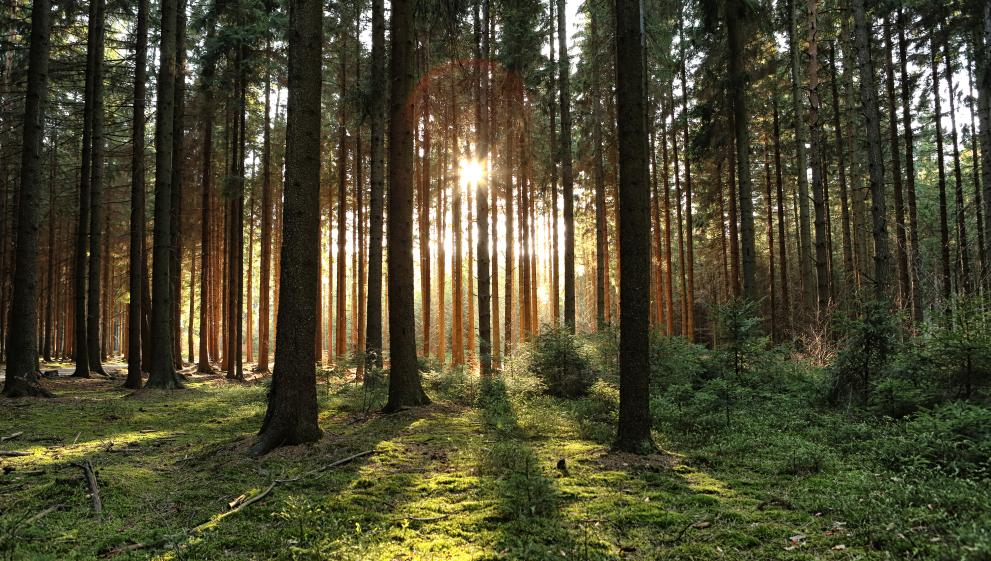

*Photo by Sergii_Petruk, Shutterstock*

I do not like long speeches so let's quickly dive in.

First, we are going to establish a baseline with both the original dataset, without any preprocessing, and then with preprocessing from previous work done on this task. Then we are going to experiment various feature engineering techniques to try and beat our baseline results. After the features, we will experiment on the model to try and further optimize our results. Finally we will interpret all the results, and present a submission to the competition.

**sources used in this notebook**

* confusion matrix with cross-validation: https://towardsdatascience.com/how-to-plot-a-confusion-matrix-from-a-k-fold-cross-validation-b607317e9874
* previous work on feature engineering: 
    * https://www.kaggle.com/c/tabular-playground-series-dec-2021/discussion/293612
    * https://www.kaggle.com/code/shouldnotbehere/two-models-random-forests/script
    * https://www.kaggle.com/code/jianyu/my-first-submission/script
* polynomial features: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html#sklearn.preprocessing.PolynomialFeatures.get_feature_names_out
* features importance: https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html
* features encoding: https://machinelearningmastery.com/autoencoder-for-classification/

All imports, and all utilities functions are in hidden cells. You can consult the code by clicking on it.

<a id='baseline'></a>
# Baseline

In [ ]:
# Load data
train_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-prediction/train.csv")
test_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-prediction/test.csv")

X = train_dataframe.drop('Cover_Type', axis='columns')
y = train_dataframe['Cover_Type']
X_train_l, X_test, y_train_l, y_test = train_test_split(X, y, test_size=0.25, random_state=73)
X_train, X_val, y_train, y_val = train_test_split(X_train_l, y_train_l, test_size=0.2, random_state=42)

sorted_labels = [1, 2, 3, 4, 5, 6, 7]

N_ESTIMATORS = 64
MAX_DEPTH = 16

### EDA

Ok, let's see what we are working with !
* **Missing values:** there is none, which means no need to add a preprocessing step for this.
* **Continuous features distribution:** all of them seem to present a Gaussian-ish bell curve, without obvious outliers. Again, no further preprocessing on this.
* **Features without variance:** Ah, we have two of them ! Soil_Type7 and Soil_Type15. We will drop them from the dataset, as they do not provide any information. 'Id' is unique to each entry, so it will be dropped as well.
* **Classes distribution:** The dataset is well-balanced.

In [ ]:
# --- UTILS ---

def EDA(X: pd.DataFrame) -> None:
    
    # Check for missing values
    print(X.isnull().sum())
    
    # Plot features distribution
    fig, ((ax0, ax1), (ax2, ax3), (ax4, ax5), (ax6,ax7), (ax8, ax9)) = plt.subplots(5, 2, figsize=(30, 20))
    axs = [ax0, ax1, ax2, ax3, ax4, ax5, ax6,ax7, ax8, ax9]
    for feature, ax in zip(X.columns[1:11], axs):
        x = X[feature].to_numpy()
        ax.hist(x, bins=50)
        ax.set_title(feature)
    plt.show()
        
    # Plot classes Distribution
    labels, counts = np.unique(X['Cover_Type'].to_numpy(), return_counts=True)
    plt.bar(labels, counts)
    plt.title('Classes distribution')
    plt.plot()
    
    # Look for features without variance
    stats = pd.DataFrame(X.describe())
    print(f"Features without variance: {[col for col in stats.columns if stats._get_value('std', col) == 0]}")

In [ ]:
EDA(train_dataframe)

In [ ]:
# --- UTILS ---

def get_features_without_variance(X: pd.DataFrame) -> list:
    # Searching for features with no variance within the dataset.
    statistical_analysis = X.describe()
    features_to_drop = []

    for feature in statistical_analysis.columns:
        if statistical_analysis._get_value('std', feature) == 0:
            features_to_drop.append(feature)
    
    return features_to_drop


def drop_features(X: pd.DataFrame, features: list, verbose: int = 0) -> pd.DataFrame:
    for feature in features:
        X = X.drop(feature, axis='columns')
        if verbose > 0:
            print(f'{feature} dropped')
    return X


def get_previous_features(X: pd.DataFrame) -> pd.DataFrame:
    new_X = X.copy()
    
    # Regarding Distances
    new_X['Highwater'] = (X['Vertical_Distance_To_Hydrology'] < 0).astype(int)
    new_X['EVDtH'] = X['Elevation'] - X['Vertical_Distance_To_Hydrology']
    new_X['EHDtH'] = X['Elevation'] - X['Horizontal_Distance_To_Hydrology']
    new_X['Euclidean_Distance_To_Hydrology'] = (X['Horizontal_Distance_To_Hydrology']**2 + X['Vertical_Distance_To_Hydrology']**2)**0.5
    new_X['Manhattan_Distance_To_Hydrology'] = X['Horizontal_Distance_To_Hydrology'] + X['Vertical_Distance_To_Hydrology']
    new_X['Hydro_Fire_1'] = X['Horizontal_Distance_To_Hydrology'] + X['Horizontal_Distance_To_Fire_Points']
    new_X['Hydro_Fire_2'] = abs(X['Horizontal_Distance_To_Hydrology'] - X['Horizontal_Distance_To_Fire_Points'])
    new_X['Hydro_Road_1'] = abs(X['Horizontal_Distance_To_Hydrology'] + X['Horizontal_Distance_To_Roadways'])
    new_X['Hydro_Road_2'] = abs(X['Horizontal_Distance_To_Hydrology'] - X['Horizontal_Distance_To_Roadways'])
    new_X['Fire_Road_1'] = abs(X['Horizontal_Distance_To_Fire_Points'] + X['Horizontal_Distance_To_Roadways'])
    new_X['Fire_Road_2'] = abs(X['Horizontal_Distance_To_Fire_Points'] - X['Horizontal_Distance_To_Roadways'])
    new_X['Horizontal_Distance_To_Roadways_Log'] = [math.log(r+1) for r in X['Horizontal_Distance_To_Roadways']]
    
    # Regarding Elevation
    new_X['Binned_Elevation'] = [math.floor(e/50.0) for e in X['Elevation']]
    
    # Regarding Soil_Types
    new_X['ST_12_32'] = X['Soil_Type12'] + X['Soil_Type32']
    new_X['ST_23_22_32_33'] = X['Soil_Type23'] + X['Soil_Type22'] + X['Soil_Type32'] + X['Soil_Type33']
    
    # Regarding Hillshade
    new_X['Hillshade_3pm_is_zero'] = (X['Hillshade_3pm'] == 0).astype(int)
    
    return new_X

In [ ]:
# Prepare both baseline datasets
features_to_drop = get_features_without_variance(train_dataframe)
features_to_drop.append('Id')
X_drop = drop_features(X_train, features_to_drop, verbose=0)
X_previous = get_previous_features(X_drop)

### Training and evaluation

The choice of a Random Forest Classifier is justified entirely by my personnal preference. I am familiar with tree algorithms, it's simple and generally efficient. 

In [ ]:
# Evaluate model on baseline dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_train.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_origin', accuracy, 'Baseline dataset, no preprocessing')

In [ ]:
# Evaluate model on baseline dataset with additional features from previous work
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_previous.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_previous', accuracy, 'Baseline with new features from previous work')

In [ ]:
plot_results()

<a id='features'></a>
# Feature Engineering experiments

### 1. Custom features

Inspired from Polynomial features and previous work I've seen on this competition. 

The problem I've had with polynomial features is that it generates a huge amount of features, without consideration for logical categories or ensembles. Results were very bad, so instead I tried to keep the idea of looking for higher dimensions features, but with some intelligence in the choice of combinations. 

In [ ]:
# --- UTILS ---

def get_custom_features(X: pd.DataFrame) -> pd.DataFrame:
    new_X = X.copy()
    
    # Regarding Distances : consider a higher dimension feature -> Volume, and a mixed Euclidean distance
    edth =  np.where(X['Euclidean_Distance_To_Hydrology'] == 0, 1, X['Euclidean_Distance_To_Hydrology'])
    hdtfp = np.where(X['Horizontal_Distance_To_Fire_Points'] == 0, 1, X['Horizontal_Distance_To_Fire_Points'])
    hdtr = np.where(X['Horizontal_Distance_To_Roadways'] == 0, 1, X['Horizontal_Distance_To_Roadways'])
    new_X['Distances_Volume'] = edth * hdtfp * hdtr
    new_X['Distances_Volume'] = [math.log(d) for d in new_X['Distances_Volume']]
    new_X['Mixed_Euclidean_Distance'] = (X['Euclidean_Distance_To_Hydrology']**2 + X['Horizontal_Distance_To_Fire_Points']**2 + X['Horizontal_Distance_To_Roadways']**2)**0.5
    
    return new_X


def EDA_new_features(X: pd.DataFrame) -> None:
    new_features = ['Distances_Volume', 'Mixed_Euclidean_Distance']
    for feature in new_features:
        plt.figure(figsize=(10, 5))
        x = X[feature].to_numpy()
        plt.hist(x, bins=50)
        plt.title(feature)
        plt.show()

In [ ]:
X_custom = get_custom_features(X_previous)

In [ ]:
EDA_new_features(X_custom)

In [ ]:
# Evaluate model on our custom dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_custom.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_custom', accuracy, 'Dataset with custom features from this notebook')

### 2. Embedding categorical features

The objective here is to see if we can maintain performances, or even improve them, but with a significant diminution of categorical features. Even after dropping a few in the EDA, we still have 38 Soil_Type features and 4 Wildness_Area features. One hot encoding does take a lot of space ! My approach is to train an Embedding layer, and then using the learnt encoded space to extract a continuous representation with fewer dimensions than the original categorical one. I arbitrarily took the square root of the original number of dimensions as my representation target, which means 8 dimensions (6 + 2) instead of 42 (38 +4).

In [ ]:
# --- UTILS ---

def get_categorical_df(X: pd.DataFrame) -> pd.DataFrame:
    not_cat_feature_columns = [col for col in X.columns if ('Soil_Type' not in col) and ('Wilderness_Area' not in col)]
    categorical_df = X.copy()
    categorical_df = drop_features(categorical_df, not_cat_feature_columns)
    return categorical_df


def get_continuous_df(X: pd.DataFrame) -> pd.DataFrame:
    cat_feature_columns = [col for col in X.columns if ('Soil_Type' in col) or ('Wilderness_Area' in col)]
    continuous_df = X.copy()
    continuous_df = drop_features(continuous_df, cat_feature_columns)
    return continuous_df


def replace_categorical_feature_by_embedded(X: pd.DataFrame, y: pd.DataFrame, cat_feature_radical: str, train: bool=True, model: object=None) -> tuple:
    # Extract targeted categorical data
    not_cat_feature_columns = [col for col in X.columns if cat_feature_radical not in col]
    targeted_df = X.copy()
    targeted_df = drop_features(targeted_df, not_cat_feature_columns)
    x_targeted = targeted_df.to_numpy()
    
    # Rule of thumb for the target embedded space dimension
    embedding_size = int(math.sqrt(x_targeted.shape[1]))
    
    # Encode sequences
    unique_sequences, counts = np.unique(x_targeted, axis=0, return_counts=True)    
    labeled_targeted= np.array([np.flatnonzero((unique_sequences == row).all(1))[0] for row in x_targeted])
    
    # Embedding model
    if train and not model:
        model = Sequential()
        model.add(Embedding(input_dim=unique_sequences.shape[0], output_dim=embedding_size, input_length=1, name="embedding"))
        model.add(Flatten())
        model.add(Dense(50, activation="relu"))
        model.add(Dense(15, activation="relu"))
        model.add(Dense(1))
        model.compile(loss="mse", optimizer="adam", metrics=["accuracy"])
        model.fit(x=labeled_targeted, y=y , epochs=50, batch_size=128, verbose=0)
    
    # Get the weights matrix
    embedding_layer = model.get_layer('embedding')
    embeddings = embedding_layer.get_weights()[0]
    
    # Make the new features using the newly created embedding space weights
    new_features = {}
    for i in range(embedding_size):
        new_features[f'{cat_feature_radical}_embedded_{str(i)}'] = []
    for index, row in targeted_df.iterrows():
        label = np.flatnonzero((unique_sequences == np.array(row)).all(1))[0]
        for i, feature in enumerate(new_features.keys()):
            new_features[feature].append(embeddings[label][i])
            
    # Concatenate the new features with old ones to create an updated Train dataset
    cat_feature_columns = [col for col in X.columns if cat_feature_radical in col]
    new_X = X.copy()
    new_X = drop_features(new_X, cat_feature_columns)
    for feature, values in new_features.items():
        new_X[feature] = values
    
    return new_X, model


def scaling(X: pd.DataFrame, train: bool=True, scaler: StandardScaler=None) -> tuple:
    
    new_X = pd.DataFrame()
    columns_to_scale = [col for col in X.columns if ('Soil_Type' not in col) and ('Wilderness_Area' not in col)]

    for feature in columns_to_scale:
        new_X[feature] = X[feature]
    
    if train and not scaler:
        scaler = StandardScaler()
        scaler.fit(new_X)        
    
    scaled_X = scaler.transform(new_X)
    scaled_X_df = pd.DataFrame(scaled_X, index=new_X.index, columns=new_X.columns)
    
    # Concat all missing features
    for col in X.columns:
        if col not in columns_to_scale:
            scaled_X_df[col] = X[col]
    
    return scaled_X_df, scaler

In [ ]:
# Separate continuous and categorical features
X_categorical = get_categorical_df(X_custom)
X_continuous = get_continuous_df(X_custom)

# Replace categorical features by features in an embedded space
X_emb, soil_type_emb_model = replace_categorical_feature_by_embedded(X_custom, y_train, 'Soil_Type')
X_emb, wilderness_area_emb_model = replace_categorical_feature_by_embedded(X_emb, y_train, 'Wilderness_Area')

# Scale continuous features
X_scaled, scaler = scaling(X_continuous)

# Regroup both categorical and continuous features
X_preprocessed = X_continuous.copy()
for col in X_emb.columns:
    if col not in X_preprocessed.columns:
        X_preprocessed[col] = X_emb[col]

In [ ]:
# Evaluate model on our custom dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_preprocessed.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_preprocessed', accuracy, 'Dataset with custom features and embedded categorical features')

### 3. Features encoding

In the same spirit than the previous operation, my objective was to add a different representation of my vectors as new features for the model to use.

This time I tried to use an autoencoder, where I would exploit the encoder after training to create new vectors and concatenate it with the original.

In [ ]:
# --- UTILS ---

def get_encoder(X: pd.DataFrame, y: pd.DataFrame, n_bottleneck: int, train: bool=True):
    n_inputs = X.shape[1]
    # define encoder
    visible = Input(shape=(n_inputs,))
    # encoder level 1
    e = Dense(n_inputs*2)(visible)
    e = BatchNormalization()(e)
    e = LeakyReLU()(e)
    # encoder level 2
    e = Dense(n_inputs)(e)
    e = BatchNormalization()(e)
    e = LeakyReLU()(e)
    # bottleneck
    bottleneck = Dense(n_bottleneck)(e)

    # define decoder, level 1
    d = Dense(n_inputs)(bottleneck)
    d = BatchNormalization()(d)
    d = LeakyReLU()(d)
    # decoder level 2
    d = Dense(n_inputs*2)(d)
    d = BatchNormalization()(d)
    d = LeakyReLU()(d)
    # output layer
    output = Dense(n_inputs, activation='linear')(d)
    
    # define autoencoder model
    model = Model(inputs=visible, outputs=output)
    model.compile(optimizer='adam', loss='mse')
    
    if train:
        X_train_, X_val_, _, _ = train_test_split(X, y, test_size=0.1, random_state=42)
        history = model.fit(X_train_, X_train_, epochs=40, batch_size=16, verbose=0, validation_data=(X_val_, X_val_))
        plt.plot(history.history['loss'], label='train')
        plt.plot(history.history['val_loss'], label='validation')
        plt.legend()
        plt.show()
    else:
        model.fit(X, X, epochs=30, batch_size=16, verbose=0)
    
    return Model(inputs=visible, outputs=bottleneck)


def encoding(X: pd.DataFrame, y: pd.DataFrame, train: bool=True, encoder: object=None) -> tuple:
    n_bottleneck = round(float(X.shape[1]) / 2.0)
    if train and not encoder:
        encoder = get_encoder(X, y, n_bottleneck, train=True)

    encoded_features = encoder.predict(X)
    encoded_X_df = pd.DataFrame(encoded_features, index=X.index)
    new_X = X.copy()
    for col in encoded_X_df.columns:
        new_X[col] = encoded_X_df[col]
    
    return encoded_X_df, encoder

In [ ]:
# Try feature encoding to see if it can improve performances
X_encoded, encoder = encoding(X_preprocessed, y_train)

In [ ]:
# Evaluate model on our custom dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_encoded.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_encoded', accuracy, 'Dataset with custom features, embedded categorical features and encoded features')

### 4. Features Importance

Last but not least, let's clean up our dataset !

Indeed, we have added a bunch of new features to help our model improve its results, but surely some of them are more useful than others. This is the point of using the feature_importances_ attribute of our model, in order to check which ones take significant place in the classification process. Again, I arbitrarily decided to setup the threshold at 1%, meaning that all features with an importance lower than this will be dropped, considered useless compared to the rest.

In [ ]:
# --- UTILS ---

def feature_importance(X: pd.DataFrame) -> pd.Series:
    rf = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
    rf.fit(X, y_train)
    
    importances = rf.feature_importances_
    std = np.std([tree.feature_importances_ for tree in rf.estimators_], axis=0)

    forest_importances = pd.Series(importances, index=X.columns)

    fig, ax = plt.subplots(figsize=(12.8,6))
    forest_importances.plot.bar(yerr=std, ax=ax)
    ax.set_title("Feature importances using MDI")
    ax.set_ylabel("Mean decrease in impurity")
    fig.tight_layout()
    
    return forest_importances

In [ ]:
features_importances = feature_importance(X_preprocessed)
threshold = 0.01
useful_columns = [col for col, importance in zip(features_importances.index, features_importances.values) if importance >= threshold]
useless_columns = [col for col in features_importances.index if col not in useful_columns]
X_clean = drop_features(X_preprocessed, useless_columns, verbose=0)

In [ ]:
# Evaluate model on our cleaned dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(rfc, X_clean.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Random Forest', 'X_clean', accuracy, 'Preprocessed dataset with most important features only')

### 5. Final pipeline

Let's put everything which worked together, and test it on our validation set !

In [ ]:
# Preprocessing pipeline
def preprocessing_pipeline(X_origin: pd.DataFrame, y: pd.DataFrame, soil_type_emb_model=None, wilderness_area_emb_model=None, scaler=None, encoder=None, train=False) -> Tuple:

    features_to_drop = get_features_without_variance(train_dataframe)
    features_to_drop.append('Id')
    X_drop = drop_features(X_origin, features_to_drop, verbose=0)

    X_previous = get_previous_features(X_drop)
    
    X_custom = get_custom_features(X_previous)
    
    X_categorical = get_categorical_df(X_custom)
    X_continuous = get_continuous_df(X_custom)

    # Pipeline for categorical features
    if train:
        X_emb, soil_type_emb_model = replace_categorical_feature_by_embedded(X_drop, y, 'Soil_Type')
        X_emb, wilderness_area_emb_model = replace_categorical_feature_by_embedded(X_emb, y, 'Wilderness_Area')
    else:
        X_emb, _ = replace_categorical_feature_by_embedded(X_drop, y, 'Soil_Type', train=False, model=soil_type_emb_model)
        X_emb, _ = replace_categorical_feature_by_embedded(X_emb, y, 'Wilderness_Area', train=False, model=wilderness_area_emb_model)

    # Pipeline for continuous features
    if train:
        X_scaled, scaler = scaling(X_continuous)
    else:
        X_scaled, _ = scaling(X_continuous, train=False, scaler=scaler)
    
    # Concatenate preprocessed continuous and categorical features
    X_preprocessed = X_continuous.copy()
    for col in X_emb.columns:
        if col not in X_preprocessed.columns:
            X_preprocessed[col] = X_emb[col]
            
    # Clean the dataset, keeping only the most important features
    X_clean = drop_features(X_preprocessed, useless_columns, verbose=0)
    
    return X_clean, soil_type_emb_model, wilderness_area_emb_model, scaler, encoder

In [ ]:
X_clean, soil_type_emb_model, wilderness_area_emb_model, scaler, encoder = preprocessing_pipeline(X_train, y_train, train=True)

In [ ]:
# Validation set compared to the baseline
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
add_result('Random Forest', 'X_val', accuracy, 'Validation set, no preprocessing')

In [ ]:
# Validation set compared to the preprocessed dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
rfc.fit(X_clean, y_train)
X_val_clean, _, _, _, _ = preprocessing_pipeline(X_val, y_val, soil_type_emb_model, wilderness_area_emb_model, scaler, encoder)
y_pred = rfc.predict(X_val_clean)
accuracy = accuracy_score(y_val, y_pred)
add_result('Random Forest', 'X_val_clean', accuracy, 'Validation set with all preprocessed features')

In [ ]:
plot_results()

These results are extremely surprising to me !

Our validation set cleary shows a brutal drop in performances due to our preprocessing pipeline. When you only look at the training set, it rather seems to improve results, with the exception of the encoding step which was left out in the final pipeline because of poor performance. In fact, with much less features than before, the final stage of our preprocessing manages to maintain a better performance than the baseline. Not by much I must admit, more or less 2%, but an improvement nonetheless.

This is exactly why we should always use a validation set I guess. My conclusion is that the preprocessing is **overfitting**, which would explain the validation set behaviour.

Ok, so let's simplify the preprocessing to fix this, keeping in mind that **less is best**.

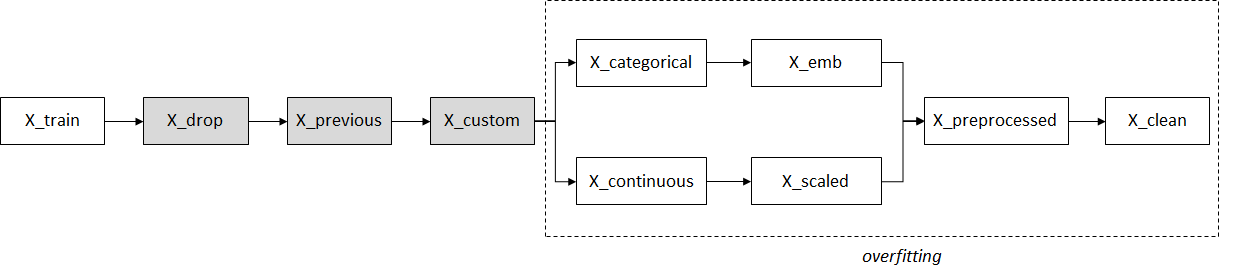

In [ ]:
# Simplified preprocessing pipeline
def simplified_preprocessing_pipeline(X_origin: pd.DataFrame) -> pd.DataFrame:

    features_to_drop = get_features_without_variance(train_dataframe)
    features_to_drop.append('Id')
    X_drop = drop_features(X_origin, features_to_drop, verbose=0)

    X_previous = get_previous_features(X_drop)
    
    X_custom = get_custom_features(X_previous)
            
    return X_custom

In [ ]:
X_custom = simplified_preprocessing_pipeline(X_train)
X_val_custom = simplified_preprocessing_pipeline(X_val)

In [ ]:
# Validation set compared to the simplified preprocessed dataset
rfc = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
rfc.fit(X_custom, y_train)
y_pred = rfc.predict(X_val_custom)
accuracy = accuracy_score(y_val, y_pred)
add_result('Random Forest', 'X_val_custom', accuracy, 'Validation set with only simplified preprocessed features')

In [ ]:
plot_results()

The overfitting hypothesis seems valid. Skipping the most training-dependent steps of the preprocessing has enabled our results to actually get better than the baseline.

Yet again, the improvement is minor with an increased accuracy of approximately 2%.

This time though, the behavour of the validation set confirms the observations on the training set, and within the same accuracy range. This builds up a bit of confidence !

<a id='models'></a>
# Models experiments

### 1. Optimize Random Forest Classifier

As explained earlier, I chose a Random Forest Classifier to perform the classification task on this problem.

The algorithm is simple enough, but still a few key parameters can help us optimize its performance. Here I will experiment with *n_estimators* and *max_depth*.

In [ ]:
def plot_scores_evolution(X: pd.DataFrame, X_val_: pd.DataFrame, y: pd.DataFrame, y_val_: pd.DataFrame) -> None:
    scores = []
    val_scores = []
    parameters = [(8, 2), (16, 4), (32, 8), (64, 16), (128, 32), (256, 64), (512, 128)]
    
    for n_estimators, max_depth in parameters:
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth)
        accuracy = evaluate_model_on_dataset(model, X.to_numpy(), y.to_numpy(), sorted_labels)
        model.fit(X, y)
        y_pred = model.predict(X_val_)
        val_accuracy = accuracy_score(y_val_, y_pred)
        accuracy = round(accuracy*100, 2)
        val_accuracy = round(val_accuracy*100, 2)
        scores.append(accuracy)
        val_scores.append(val_accuracy)

    plt.figure(figsize=(10, 5))
    plt.plot(np.arange(len(scores)), scores, label='accuracy')
    plt.plot(np.arange(len(val_scores)), val_scores, label='val_accuracy')
    plt.title('Accuracy evolution relative to model parameters complexity')
    plt.legend()
    plt.show()

In [ ]:
plot_scores_evolution(X_custom, X_val_custom, y_train, y_val)

In total 7 combinations of increasing complexity were tested. We can see on the graph above that there is no need to go behond (n_estimators=64, max_depth=16) and (n_estimators=128, max_depth=32), after which we simply risk overfitting without any significant reward in performance.

### 2. Meta-model

The origin of this idea is in a notebook by SHEER (see sources in the Introduction section). Basically it is about training some sub-models on specific classes of the dataset.

My take on this idea was to use these sub-models to create new information to give to a meta-model, in addition of the probabilities already computed by the Random Forest Classifier.

The choice of ensembles to train the sub-models was made by observing the confusion matrices in the notebook. The objective was to regroup the main missclassified classes together, wich are 1-2 and 3-6.

Below is a simple graph to summarize the process.

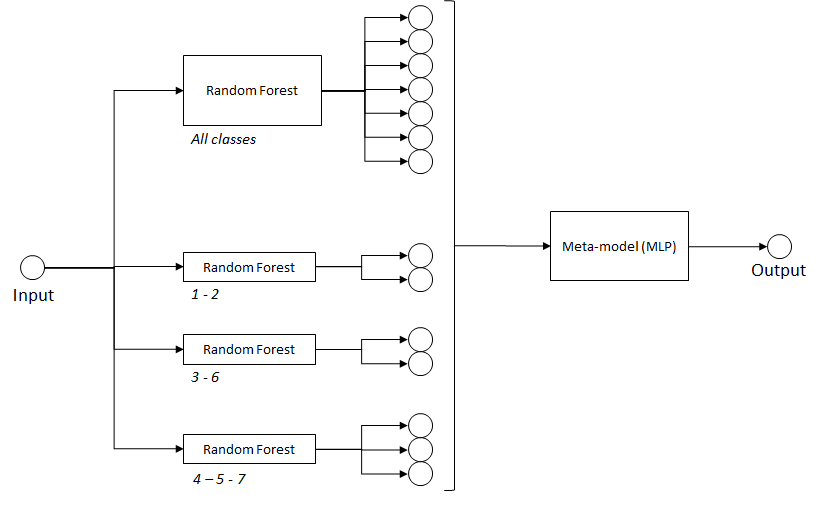

In [ ]:
# Make a new dataset with vectors using both generic and specific predictions
def make_meta_dataset(X: pd.DataFrame, y: pd.DataFrame, rfc_1_2=None, rfc_3_6=None, rfc_4_5_7=None, rfc=None, train=False) -> pd.DataFrame:
    
    X_vectors = []
    
    if train:
        # 1 and 2
        X_1_2 = X.to_numpy()[np.argwhere(y.to_numpy() <= 2)].squeeze()
        y_1_2 = y.to_numpy()[np.argwhere(y.to_numpy() <= 2)]
        rfc_1_2 = RandomForestClassifier(n_estimators=64, max_depth=16)
        # 6 and 3
        indices = np.argwhere((y.to_numpy() == 3) | (y.to_numpy() == 6))
        X_3_6 = X.to_numpy()[indices].squeeze()
        y_3_6 = y.to_numpy()[indices]
        rfc_3_6 = RandomForestClassifier(n_estimators=64, max_depth=16)
        # 4, 5 and 7
        indices = np.argwhere((y.to_numpy() == 4) | (y.to_numpy() == 5) | (y.to_numpy() == 7))
        X_4_5_7 = X.to_numpy()[indices].squeeze()
        y_4_5_7 = y.to_numpy()[indices]
        rfc_4_5_7 = RandomForestClassifier(n_estimators=64, max_depth=16)
        # All
        rfc = RandomForestClassifier(n_estimators=128, max_depth=32)
        
        rfc_1_2.fit(X_1_2, y_1_2)
        rfc_3_6.fit(X_3_6, y_3_6)
        rfc_4_5_7.fit(X_4_5_7, y_4_5_7)
        rfc.fit(X, y)

    pred_1_2 = rfc_1_2.predict_proba(X)
    pred_3_6 = rfc_3_6.predict_proba(X)
    pred_4_5_7 = rfc_4_5_7.predict_proba(X)
    pred = rfc.predict_proba(X)

    for i in range(X.shape[0]):
        vector = [
            pred_1_2[i][0], pred_1_2[i][1], pred_3_6[i][0], pred_3_6[i][1], pred_4_5_7[i][0], pred_4_5_7[i][1], pred_4_5_7[i][2],
            pred[i][0], pred[i][1], pred[i][2], pred[i][3], pred[i][4], pred[i][5], pred[i][6]
        ]
        X_vectors.append(vector)

    X_vectors = np.asarray(X_vectors)
    return X_vectors, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc


# Build the meta-model
def get_ohe_y(y) -> np.array:
    ohe_y = []
    for label in y:
        new_label = np.zeros(7)
        new_label[label-1] = 1
        ohe_y.append(new_label)
    ohe_y = np.asarray(ohe_y)
    return ohe_y


def get_meta_model(X: pd.DataFrame, y: pd.DataFrame, epochs: int=10, X_val_=None, y_val_=None, train=False) -> Tuple:
    input_layer = Input(shape=(X.shape[1],))
    net = Dense(16, activation='relu')(input_layer)
    net_drop = Dropout(0.2)(net)
    output_layer = Dense(7, activation='sigmoid')(net_drop)

    meta_model = Model(inputs=input_layer, outputs=output_layer)
    optimizer = adam_v2.Adam(learning_rate=1e-3)
    meta_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['acc'])
    
    ohe_y = get_ohe_y(y)
    
    if train:
        y_val_ = get_ohe_y(y_val_)
        history = meta_model.fit(X, ohe_y, epochs=epochs, batch_size=64, verbose=0, validation_data=(X_val_, y_val_))
        accuracy = history.history['val_acc'][-1]
        
        plt.figure(figsize=(10, 5))
        plt.plot(history.history['loss'], label='train')
        plt.plot(history.history['val_loss'], label='validation')
        plt.legend()
        plt.show()
        
        plt.figure(figsize=(10, 5))
        plt.plot(history.history['acc'], label='train')
        plt.plot(history.history['val_acc'], label='validation')
        plt.legend()
        plt.show()
    else:
        history = meta_model.fit(X, ohe_y, epochs=epochs, batch_size=64, verbose=0)
        accuracy = None
    
    return meta_model, accuracy

In [ ]:
X_vectors, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc = make_meta_dataset(X_custom, y_train, train=True)
X_val_vectors, _, _, _, _ = make_meta_dataset(X_val_custom, y_val, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc)
_, accuracy = get_meta_model(X_vectors, y_train, 10, X_val_vectors, y_val, train=True)
add_result('Meta-model', 'X_val_vectors', accuracy, 'RFC predictions of validation set enriched by specific sub-models')

The meta-model seems to work wonders for the training set, but to have a limited impact on the validation set. Overfitting really is the ennemy here !

Let's stop at 4 epochs for the training then.

<a id='results'></a>
# Results overview

Ok now the decisive moment, time to use everything on the Test set !

First let's retrain all models using both the training and the validation sets, we need all we can have.

Then I will execute the whole process on the Test set in order to check our hypothesis and results.

In [ ]:
# Retrain all models with training + validation sets
X_clean, soil_type_emb_model, wilderness_area_emb_model, scaler, encoder = preprocessing_pipeline(X_train_l, y_train_l, train=True)
X_custom = simplified_preprocessing_pipeline(X_train_l)
X_vectors, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc = make_meta_dataset(X_custom, y_train_l, train=True)
meta_model, _ = get_meta_model(X_vectors, y_train_l, epochs=4)

In [ ]:
# Process the Test set
X_test_clean, _, _, _, _ = preprocessing_pipeline(X_test, y_test, soil_type_emb_model, wilderness_area_emb_model, scaler, encoder)
X_test_custom = simplified_preprocessing_pipeline(X_test)
X_test_vectors, _, _, _, _ = make_meta_dataset(X_test_custom, y_test, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc)

In [ ]:
# Test set against the baseline
rfc_baseline = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
rfc_baseline.fit(X_train_l, y_train_l)
y_pred = rfc_baseline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
add_result('Random Forest', 'X_test', accuracy, 'Test set, no preprocessing')

In [ ]:
# Test set against the simplified preprocessed set
y_pred = rfc.predict(X_test_custom)
accuracy = accuracy_score(y_test, y_pred)
add_result('Random Forest', 'X_test_custom', accuracy, 'Test set with only simplified preprocessed features')

In [ ]:
# Test set against the fully preprocessed set
rfc_overfit = RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
rfc_overfit.fit(X_clean, y_train_l)
y_pred = rfc_overfit.predict(X_test_clean)
accuracy = accuracy_score(y_test, y_pred)
add_result('Random Forest', 'X_test_clean', accuracy, 'Preprocessed Test set')

In [ ]:
# Test set against the meta-model
y_pred = meta_model.predict(X_test_vectors)
y_pred = np.asarray([np.argmax(pred) + 1 for pred in y_pred])
accuracy = accuracy_score(y_test, y_pred)
add_result('Meta-model', 'X_test_vectors', accuracy, 'RFC predictions enriched by specific sub-models')

In [ ]:
plot_results()

Conclusions about our results:

**Feature Engineering**
* The full preprocessing which we suspected to overfit, definitely does. We have a double-checked confirmation with the Validation and the Test sets.
* On the contrary, the simplified preprocessing remains effective with an approximative increase between 2% and 3%.

**Models**
* The Random Forest Classifier performs well, without any added complexity.
* The Meta-model gives mixed results: on the one hand we have a clean 1% increase in accuracy for the Validation set, on the other hand we have a almost perfectly similar result for the Test set (0.03% to 0.2% difference depending on the run). This time I will give the meta-model the benefit of doubt and keep it in the final pipeline for the submission.

<a id='submission'></a>
# Submission

In [ ]:
# Retrain on the full dataset
X_train_full = train_dataframe.drop('Cover_Type', axis='columns')
y_train_full = train_dataframe['Cover_Type']
X_custom_full = simplified_preprocessing_pipeline(X_train_full)
X_vectors_full, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc = make_meta_dataset(X_custom_full, y_train_full, train=True)
meta_model, _ = get_meta_model(X_vectors_full, y_train_full, epochs=4)

In [ ]:
# Process the submission test
X_submit_custom = simplified_preprocessing_pipeline(test_dataframe)
X_submit_vectors, _, _, _, _ = make_meta_dataset(X_submit_custom, None, rfc_1_2, rfc_3_6, rfc_4_5_7, rfc)
y_pred = meta_model.predict(X_submit_vectors)
y_pred = np.asarray([np.argmax(pred) + 1 for pred in y_pred])

In [ ]:
# Submit
submission_df = pd.DataFrame()
submission_df['Id'] = test_dataframe['Id']
submission_df['Cover_Type'] = y_pred
submission_df.to_csv('submission.csv', index=False)

<a id='conclusion'></a>
# Conclusion

We are not finished with this one !

Indeed, despite the very interesting things I learnt regarding feature engineering, and the fun tests with the meta-model, I was not able to significantly improved the results above the baseline. In fact it is just a few percents above, the bare minimum to be called an increase. Don't get me wrong, it is still something. But I'm hoping to do better using another method unexploited so far in this notebook: **Data augmentation** ! 

See you then ;) 

I'm always open to constructive criticism in order to improve, please don't hesitate to give any feedback :) 